# 🧪 LAB: Machine Learning to Predict Concrete Compressive Strength

In this lab, you will apply `PyTorch` to a real-world data problem. You will implement a Neural Network in `PyTorch` using the new functionalities introduced this week and compare its performance with a Support Vector Machine and Linear Regression.

Your goal is to predict the **compressive strength of concrete** (the outcome variable, *Y*) based on a set of input features (*X*), including:
**Cement, Blast Furnace Slag, Fly Ash, Water, Superplasticizer, Coarse Aggregate, Fine Aggregate, and Age.**

This dataset and problem are based on the following paper:

- I-Cheng Yeh, "Modeling of strength of high performance concrete using artificial neural networks," Cement and Concrete Research, Vol. 28, No. 12, pp. 1797-1808 (1998). [Link to the paper](yeh1998.pdf).


---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.

NAME(s) = "Chloe Wang, Ethan Ooi, Namitha Tholasi"

## 0. Overall Instructions 

In this lab, you will work with three models: a **Neural Network**, a **Support Vector Machine (SVM)**, and some form of **Linear Regression**. Each should meet the following requirements:

- **Do not tune the models**. For example, for the Neural Network, choose any number of layers and hidden units you prefer; for the SVM, select a kernel of your choice (e.g., linear, RBF, polynomial), etc.

- **Evaluate model performance using k-fold cross-validation**. That is, run each model using a chosen number of folds (*k*), and report the average performance across all folds. You may select the value of *k* that you want.

- **Be careful with data preprocessing**. Apply all preprocessing steps properly to avoid data leakage (e.g. standardizing features before data splitting)

## 1. Pre-implementation Group Discussion (15 points)

In your group, discuss, agree on, and elaborate the following points:

- **Descriptive analysis**. Identify what exploratory or descriptive analyses you can perform to better understand the relationship between each input variable and the outcome. Consider both visual (e.g., scatter plots, histograms) and statistical summaries.

- **Data preprocessing**. Decide what preprocessing steps are necessary given that you will be using neural networks. 

- **Model configuration**. Specify which cost function and output layer activation are most appropriate for your problem type (e.g., regression vs. classification). Explain your reasoning based on the nature of the outcome variable.

- **Performance evaluation**. Describe how you will perform k-fold cross-validation to assess your model’s performance. Include how you will divide the data, compute metrics across folds, and report the final averaged results.

## 1. Pre-implementation Group Discussion

**Descriptive analysis** 

We will use summary statistics and check for missing values. Histograms will show how each variable is distributed, and scatter plots will show how each input relates to concrete strength. A correlation heatmap will show which inputs matter most, like Cement and Age.

**Data preprocessing**

The features are on very different scales, so we will standardize them to mean 0 and standard deviation 1, which helps the neural network and SVM. To avoid data leakage, we will fit the scaler only on the training data in each fold, then apply it to that fold's test data.

**Model configuration** 

Concrete strength is a continuous number, so this is a regression problem. The output layer will have one neuron with a linear activation so it can predict any value. We will use Mean Squared Error (MSE) as the cost function because it is the standard choice for regression.

**Performance evaluation** 

We will use 5-fold cross-validation, with the data shuffled and split into 5 equal parts. Each model is trained on 4 parts and tested on the remaining part, five times in total. All three models use the same folds. We will report the average RMSE and R² across the 5 folds for each model.

## 2. Descriptive analysis (10 points)

Apply the descriptive analyses that your group agreed upon in the previous section.

**Load the dataset before beginning the descriptive analysis; you will also use it in the following sections.**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#Load the dataset
df = pd.read_excel("Concrete_Data.xls")

#Shorten the long original column names
df.columns = ["Cement", "Slag", "FlyAsh", "Water", "Superplasticizer",
              "CoarseAgg", "FineAgg", "Age", "Strength"]
print(df.shape)
df.head()

Matplotlib is building the font cache; this may take a moment.


(1030, 9)


,Cement,Slag,FlyAsh,Water,Superplasticizer,CoarseAgg,FineAgg,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [2]:
#Check data quality and summarize each variable
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Zeros per column:\n", (df == 0).sum())
df.describe().round(2).T

Missing values: 0
Duplicate rows: 25
Zeros per column:
 Cement                0
Slag                466
FlyAsh              566
Water                 0
Superplasticizer    379
CoarseAgg             0
FineAgg               0
Age                   0
Strength              0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
Cement,1030.0,281.17,104.51,102.00,192.38,272.90,350.00,540.0
Slag,1030.0,73.90,86.28,0.00,0.00,22.00,142.95,359.4
FlyAsh,1030.0,54.19,64.00,0.00,0.00,0.00,118.27,200.1
Water,1030.0,181.57,21.36,121.75,164.90,185.00,192.00,247.0
Superplasticizer,1030.0,6.20,5.97,0.00,0.00,6.35,10.16,32.2
CoarseAgg,1030.0,972.92,77.75,801.00,932.00,968.00,1029.40,1145.0
FineAgg,1030.0,773.58,80.18,594.00,730.95,779.51,824.00,992.6
Age,1030.0,45.66,63.17,1.00,7.00,28.00,56.00,365.0
Strength,1030.0,35.82,16.71,2.33,23.71,34.44,46.14,82.6


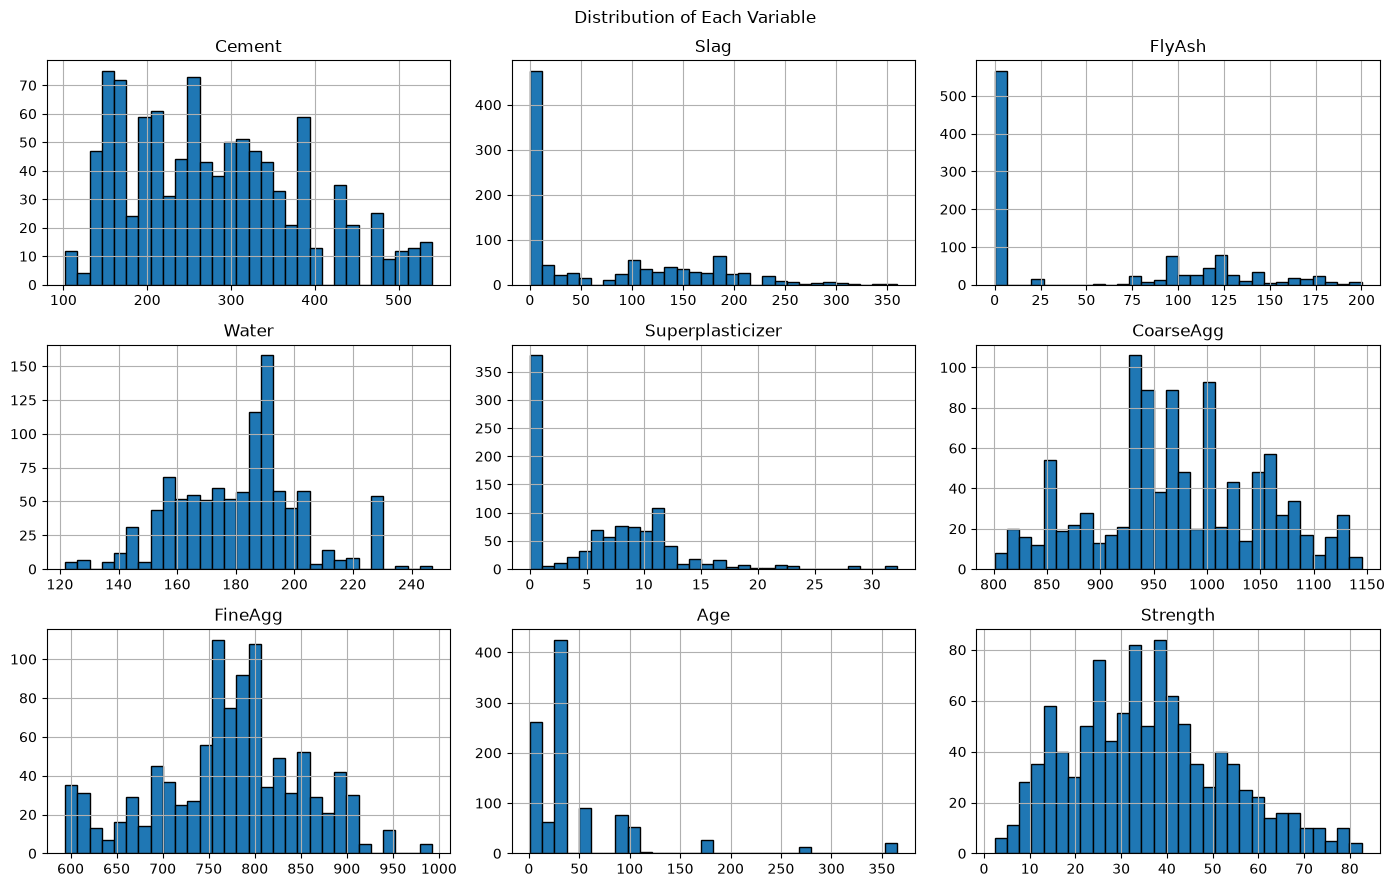

In [3]:
#Distribution of every variable
df.hist(bins=30, figsize=(14, 9), edgecolor="black")
plt.suptitle("Distribution of Each Variable")
plt.tight_layout()
plt.show()

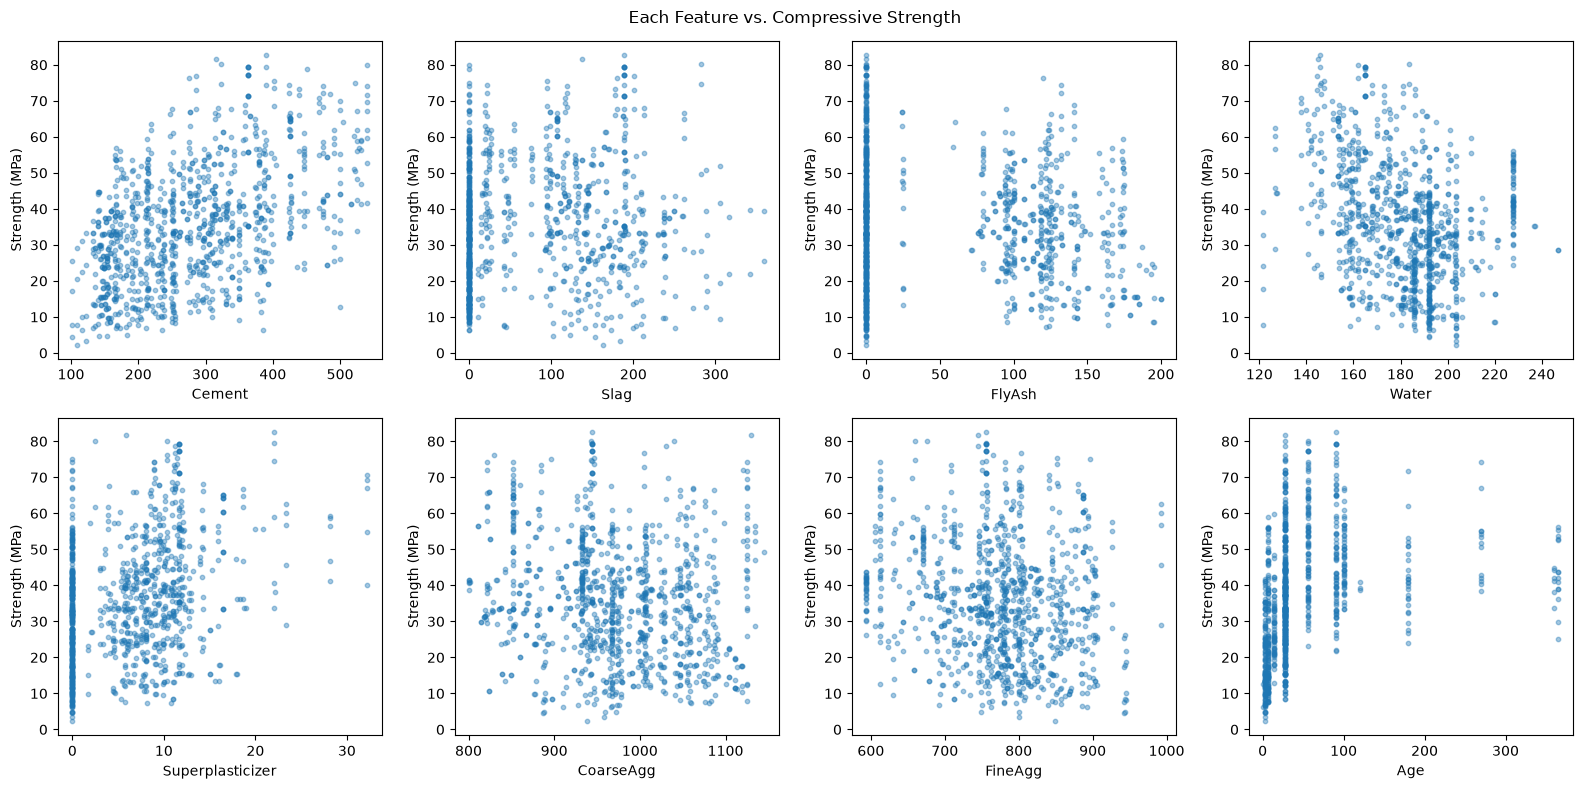

In [5]:
#Relationship between each input and the outcome
features = df.columns.drop("Strength")
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, col in zip(axes.flat, features):
    ax.scatter(df[col], df["Strength"], alpha=0.4, s=10)
    ax.set_xlabel(col)
    ax.set_ylabel("Strength (MPa)")
plt.suptitle("Each Feature vs. Compressive Strength")
plt.tight_layout()
plt.show()

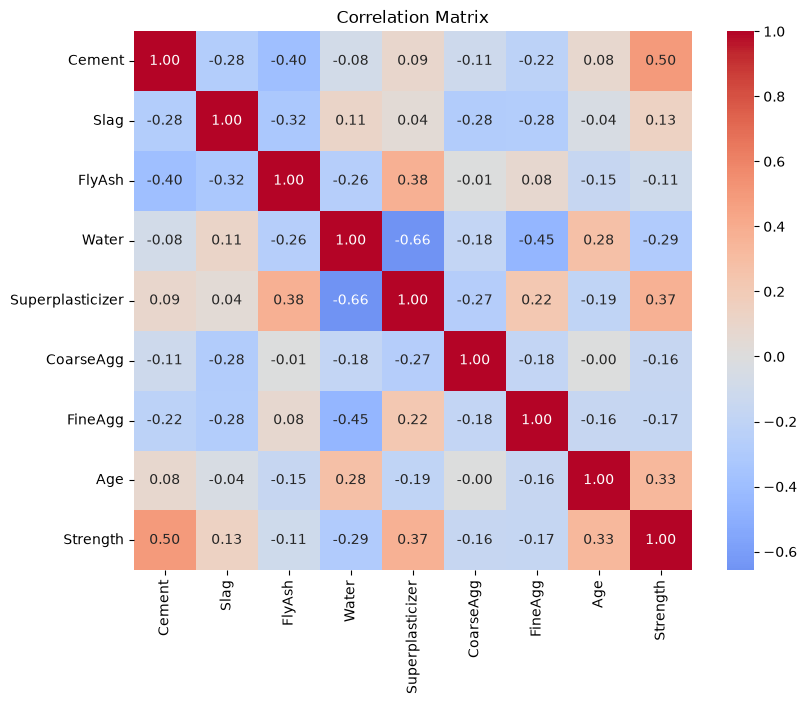

,Pearson,Spearman
Cement,0.50,0.48
Superplasticizer,0.37,0.35
Age,0.33,0.60
Slag,0.13,0.16
FlyAsh,-0.11,-0.08
CoarseAgg,-0.16,-0.18
FineAgg,-0.17,-0.18
Water,-0.29,-0.31


In [ ]:
#Correlation heatmap across all variables
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix")
plt.show()

#Correlation of each feature with Strength
pd.DataFrame({
    "Pearson": df.corr()["Strength"],
    "Spearman": df.corr(method="spearman")["Strength"],
}).drop("Strength").sort_values("Pearson", ascending=False).round(2)

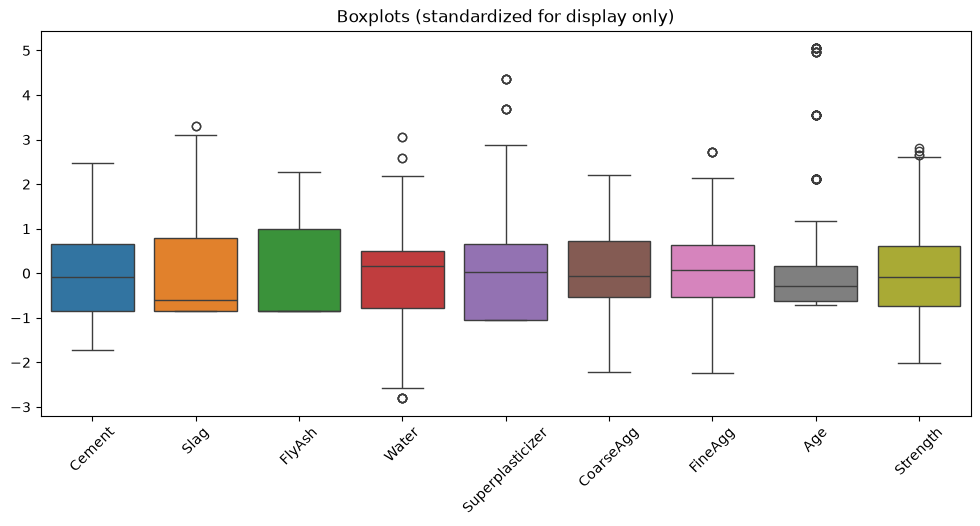

In [ ]:
#Standardized only so all variables fit on one plotgit fetch
df_scaled = (df - df.mean()) / df.std()
plt.figure(figsize=(12, 5))
sns.boxplot(data=df_scaled)
plt.title("Boxplots (standardized for display only)")
plt.xticks(rotation=45)
plt.show()

## 3. Neural Network (40 points)

Implement a neural network as you did in the previous lab, but this time leverage the new functionalities introduced this week. Specifically:

- Your class implementing the neural network should inherit from nn.Module.

- Use `nn.Linear` for the linear transformations between layers, `nn.ReLU` for the hidden-layer activations, and the appropriate activation function for the output layer (e.g., `nn.Sigmoid` for binary classification).

- Use the appropriate cost function from `torch.nn` for your task (e.g., `nn.MSELoss`, `nn.BCELoss`).

- Use Adam from `torch.optim` as the optimizer.

- Use `DataLoader` to efficiently do batch processing. You may choose the batch size freely.

Once you have implemented this class, create an instance of it, then train and evaluate your model on the lab dataset.

**Remember to follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.**

In [4]:
# USE AS MANY CELLS AS NEEDED

## 4. Replication (10 points)

Replicate your neural network experiment using the corresponding model class from `scikit-learn`: https://scikit-learn.org/stable/api/sklearn.neural_network.html. Be sure to apply the same neural network architecture as well as the same procedures for model evaluation and preprocessing to ensure a fair comparison.

**Remember**: Follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.

In [5]:
# USE AS MANY CELLS AS NEEDED

## 5. Comparison (20 points)

Apply a Support Vector Machine (SVM) and Linear Regression model to the dataset, and compare their performance with that of your Neural Network.

Discuss any similarities or differences you observe in their results and provide possible explanations for these patterns.

Be sure to apply the k-fold cross-validation procedure to ensure a fair comparison across all models.

**Remember**: Follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.

In [6]:
# USE AS MANY CELLS AS NEEDED

## 6. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

YOUR TEXT HERE